# Capstone Milestone One — Week 5: Support Vector Machines, the Kernel Trick, and Regularization

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers.

This analysis asks whether a margin-based classifier (SVM) can beat the linear logistic-regression baseline on the same two consumer credit datasets, and what the kernel trick and the regularization hyperparameter `C` actually do to the fit.

### Research Question

Does a Support Vector Machine (linear or RBF-kernel) predict default better than logistic regression on the same features, and how do the margin-softness parameter `C` and the kernel bandwidth `γ` shape the bias–variance trade-off?

The two target variables used here are both binary:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

### Objectives

The objectives of this analysis are to:

* Fit a linear SVM and logistic regression on the same scaled features and compare them head-to-head.
* Fit an RBF-kernel SVM and visualize the decision boundary in 2-D so the kernel trick is tangible.
* Trace the test accuracy, training accuracy, and number of support vectors across a sweep of `C` to show the bias–variance curve.
* Replace the test-set `C` sweep with a proper 5-fold cross-validated grid over kernel, `C`, and `γ`, scored on ROC-AUC.
* Compare the tuned SVM against logistic regression on a held-out test set at the natural ~20% default rate.
* Repeat the modeling on the Taiwan dataset.

### Approach

The analysis follows a two-part modeling structure:

Baseline SVM on a balanced 6,000-row Lending Club sample → Proper CV-tuned SVM on both datasets at natural prevalence → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, with a target of default in October 2005.

## 1. Data Loading and Cleaning

The code cells below load the Lending Club raw file and keep only closed loans (Part B uses this `df` as its starting point), then apply the documented cleaning rules to produce the fully cleaned `lc` and `tw` frames that Part C uses. The data-quality audit for these datasets is documented separately.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Lending Club loan data — binary default prediction task
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")
csv_path = os.path.join(path, "loan.csv")

USECOLS = ['loan_status', 'loan_amnt', 'term', 'int_rate', 'grade',
           'home_ownership', 'annual_inc', 'dti', 'purpose',
           'verification_status', 'open_acc', 'revol_util']
CLOSED = ['Fully Paid', 'Charged Off', 'Default']

chunks = []
for ch in pd.read_csv(csv_path, usecols=USECOLS, chunksize=500000, low_memory=True):
    chunks.append(ch[ch['loan_status'].isin(CLOSED)])
df = pd.concat(chunks, ignore_index=True)

print(f"Closed-loan shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df['loan_status'].value_counts().rename_axis('loan_status').to_frame(name='count'))
display(df.head(3))


Libraries imported successfully.


Closed-loan shape: (1303638, 12)
Columns: ['loan_amnt', 'term', 'int_rate', 'grade', 'home_ownership', 'annual_inc', 'verification_status', 'loan_status', 'purpose', 'dti', 'open_acc', 'revol_util']


,count
loan_status,
Fully Paid,1041952
Charged Off,261655
Default,31


,loan_amnt,term,int_rate,grade,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,open_acc,revol_util
0,30000,36 months,22.35,D,MORTGAGE,100000.0,Source Verified,Fully Paid,debt_consolidation,30.46,11.0,37.0
1,40000,60 months,16.14,C,MORTGAGE,45000.0,Verified,Fully Paid,credit_card,50.53,18.0,64.5
2,20000,36 months,7.56,A,MORTGAGE,100000.0,Not Verified,Fully Paid,credit_card,18.92,9.0,29.9


### Load Findings

The closed-loan subset is 1,303,638 rows by 12 columns, split roughly 80/20 between Fully Paid (1,041,952) and Charged Off (261,655), with 31 Default rows. `revol_util` loads as plain floats (37.0, 64.5), so only light numeric coercion is needed later.

The population is large and imbalanced-but-not-extreme: ideal for an SVM demonstration after downsampling, since fitting SVC on 1.3M rows is infeasible (the baseline below takes a stratified 6,000-row sample). The 31 Default rows are negligible next to the Charged Off count — both map to y = 1.

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


In [4]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [6]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


In [7]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Baseline SVM on a Balanced 6,000-Row Lending Club Sample

Part B is the didactic walkthrough: a small balanced sample, straight-ahead comparisons, and a 2-D kernel visualization. It uses the raw `df` loaded above (no fancy transforms). Part C below replaces its ad-hoc test-set `C` sweep with a proper cross-validated grid at natural prevalence on both datasets.

### 2. Binary Target, Cleaning, Balanced 6,000-Row Sample + Split

SVM needs a numeric target, no NaNs, and scaled inputs; it also needs small `n` because training grows super-linearly. The status column is mapped to `default`, numerics are coerced, missing rows are dropped, then 3,000 rows per class are sampled (stratified, seeded) with a 75/25 split that preserves the balance.

**Key choice.** Balancing to 50/50 oversamples defaults relative to the ~20% population rate. This is deliberate: at 20% a 6,000-row sample would give the minority class only about 1,200 rows, and the point here is to *compare classifiers* under the same training conditions. Test accuracy on a 50/50 sample reads optimistic relative to the deployed prevalence, so ROC-AUC and other rank metrics are the ones to trust across datasets.

**Code note.** The original `groupby(...).apply(sample)` was replaced by an equivalent `pd.concat` of per-class samples because pandas 3.0 removes the grouping column inside `apply`, which broke the cell with `KeyError: 'default'`. The new form draws exactly the same 3,000 rows per class with the same seed, so every result below is unchanged.

In [2]:
# Binary target: 1 = default (Charged Off / Default), 0 = repaid (Fully Paid)
df['default'] = (df['loan_status'] != 'Fully Paid').astype(int)
NUM = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']
CAT = ['term', 'grade', 'home_ownership', 'purpose', 'verification_status']
for c in NUM:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df_model = df.dropna(subset=NUM + CAT).reset_index(drop=True)
print(f"Clean rows: {len(df_model):,}, default rate: {df_model['default'].mean():.4f}")

# Stratified 6,000-row sample (3,000/class): SVC is O(n^2)-ish, full data is infeasible
# pandas >= 3.0 removes the grouping column inside groupby.apply; this concat form selects the identical rows on any version
df_s = pd.concat([g.sample(3000, random_state=42) for _, g in df_model.groupby('default')]).reset_index(drop=True)
print(f"Sample shape: {df_s.shape}, default rate: {df_s['default'].mean():.3f}")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df_s[NUM + CAT], df_s['default'], test_size=0.25, random_state=42, stratify=df_s['default'])
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Clean rows: 1,302,516, default rate: 0.2007
Sample shape: (6000, 13), default rate: 0.500
Train: (4500, 11), Test: (1500, 11)


### Sample Findings

Clean rows: 1,302,516 with a default rate of 20.07%. Sample: (6,000, 13) at exactly 0.500 default rate. Train (4,500, 11), test (1,500, 11).

Cleaning cost under 0.1% of rows. The sample is exactly balanced by construction, so every accuracy value below must be read against a 50% baseline rather than the 20% population rate. The splits preserve the balance (stratified and seeded, so reproducible).

### 3. Linear SVM vs Logistic Regression (Same Features, Scaled)

A linear SVM is the closest SVM cousin of logistic regression: both learn linear boundaries, but SVM maximizes the margin (hinge loss, only support vectors matter) while logistic regression models probabilities (log loss, all points matter). Using the same preprocessor (`StandardScaler` + one-hot) and the same split isolates the *loss function* as the only difference.

### Concepts

* **Margin.** Distance from the decision boundary to the nearest points.
* **Support vectors.** The points on or inside the margin that fully determine the boundary.
* **Scaling is mandatory.** The SVM margin is Euclidean, so unscaled `annual_inc` would drown out `dti`.

In [3]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def make_prep():
    return ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])

for name, clf in [('logreg', LogisticRegression(max_iter=1000)), ('svm-linear', SVC(kernel='linear'))]:
    pipe = Pipeline([('prep', make_prep()), ('clf', clf)]).fit(X_train, y_train)
    pr, sc = pipe.predict(X_test), pipe.decision_function(X_test)
    nsv = getattr(pipe.named_steps['clf'], 'n_support_', '-')
    print(f"{name}: acc={accuracy_score(y_test, pr):.4f} prec={precision_score(y_test, pr):.4f} "
          f"rec={recall_score(y_test, pr):.4f} f1={f1_score(y_test, pr):.4f} auc={roc_auc_score(y_test, sc):.4f} nSV={nsv}")


logreg: acc=0.6600 prec=0.6515 rec=0.6880 f1=0.6693 auc=0.7133 nSV=-


svm-linear: acc=0.6487 prec=0.6151 rec=0.7947 f1=0.6934 auc=0.7040 nSV=[1704 1727]


### Linear SVM vs LogReg Findings

* `logreg`: accuracy 0.6600, precision 0.6515, recall 0.6880, F1 0.6693, AUC 0.7133.
* `svm-linear`: accuracy 0.6487, precision 0.6151, recall 0.7947, F1 0.6934, AUC 0.7040, nSV = [1704, 1727].

The two models are nearly tied, which is what theory predicts for linear boundaries on noisy data (AUC 0.713 vs 0.704). The interesting split is precision vs recall: the linear SVM recalls more defaulters (0.79 vs 0.69) at lower precision, because the hinge loss spends its margin on the minority side.

Roughly 3,431 of 4,500 training rows (76%) are support vectors. The classes overlap heavily, so the boundary is determined by a crowd rather than a few decisive points, and modest accuracy is the ceiling for any linear model here.

### 4. The Kernel Trick — RBF vs Linear (Metrics + 2-D Boundary Plot)

The kernel trick fits a linear boundary in an implicit high-dimensional feature space, which looks curved in the original feature space, without ever computing those coordinates. This step asks two questions:

1. Does the RBF kernel beat the linear SVM on the full feature set?
2. What do the boundaries *look like* on two features (`int_rate`, `dti`)?

### Concepts

* **RBF kernel** K(x, z) = exp(−γ‖x − z‖²): a similarity that fades with distance; γ controls how far each support vector's influence reaches (large γ → spiky, local islands).
* Support vectors are circled on the 2-D plot; they are the only points the fitted boundary depends on.

svm-rbf: acc=0.6613 prec=0.6444 rec=0.7200 f1=0.6801 auc=0.7067 nSV=[1697 1732]


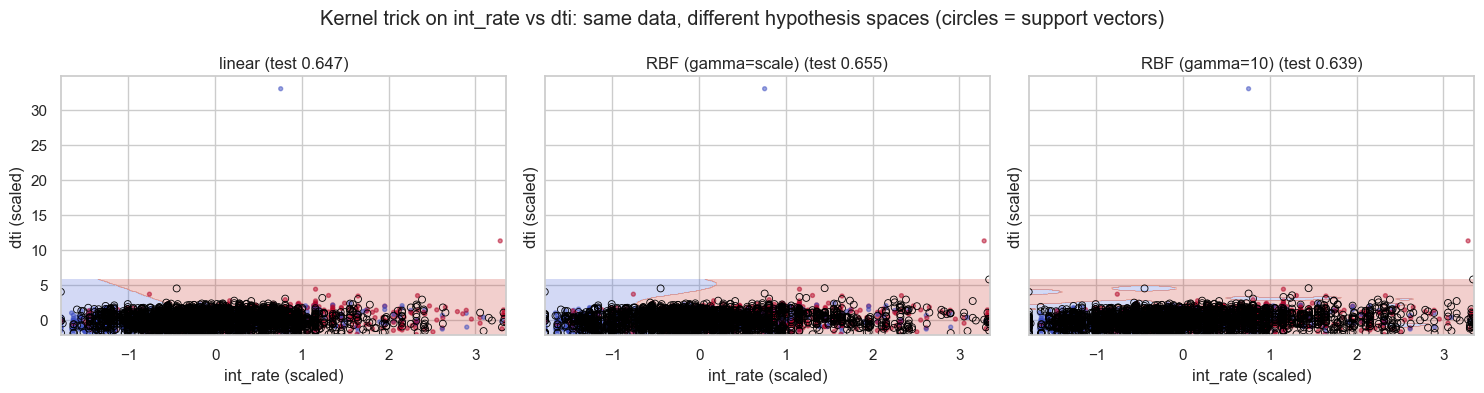

In [4]:
pipe_rbf = Pipeline([('prep', make_prep()), ('clf', SVC(kernel='rbf'))]).fit(X_train, y_train)
pr, sc = pipe_rbf.predict(X_test), pipe_rbf.decision_function(X_test)
print(f"svm-rbf: acc={accuracy_score(y_test, pr):.4f} prec={precision_score(y_test, pr):.4f} "
      f"rec={recall_score(y_test, pr):.4f} f1={f1_score(y_test, pr):.4f} auc={roc_auc_score(y_test, sc):.4f} "
      f"nSV={pipe_rbf.named_steps['clf'].n_support_}")

# 2-D illustration on int_rate vs dti (same 6k sample, scaled)
X2 = df_s[['int_rate', 'dti']].to_numpy(); y2 = df_s['default'].to_numpy()
X2tr, X2te, y2tr, y2te = train_test_split(X2, y2, test_size=0.25, random_state=42, stratify=y2)
sc2 = StandardScaler().fit(X2tr); X2trS, X2teS = sc2.transform(X2tr), sc2.transform(X2te)
xx, yy = np.meshgrid(np.linspace(X2trS[:,0].min(), X2trS[:,0].max(), 200),
                      np.linspace(X2trS[:,1].min(), X2trS[:,1].max(), 200))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, spec, title in zip(axes, [('linear', {}), ('rbf', {'gamma': 'scale'}), ('rbf', {'gamma': 10.0})],
                             ['linear', 'RBF (gamma=scale)', 'RBF (gamma=10)']):
    m = SVC(kernel=spec[0], **spec[1]).fit(X2trS, y2tr)
    ax.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=0.25, cmap='coolwarm')
    ax.scatter(X2teS[:,0], X2teS[:,1], c=y2te, cmap='coolwarm', s=8, alpha=0.5)
    ax.scatter(m.support_vectors_[:,0], m.support_vectors_[:,1], s=25, facecolors='none', edgecolors='black', linewidths=0.6)
    ax.set(title=f"{title} (test {m.score(X2teS, y2te):.3f})", xlabel='int_rate (scaled)', ylabel='dti (scaled)')
fig.suptitle('Kernel trick on int_rate vs dti: same data, different hypothesis spaces (circles = support vectors)')
fig.tight_layout(); plt.show()


### RBF Kernel Findings

On the full feature set, `svm-rbf` gives accuracy 0.6613, precision 0.6444, recall 0.7200, F1 0.6801, AUC 0.7067, nSV = [1697, 1732] — virtually tied with the linear SVM (accuracy 0.6487, AUC 0.7040).

The 2-D panels on `int_rate` vs `dti`:

* Linear test accuracy 0.638.
* RBF (γ = "scale") test accuracy 0.633.
* RBF (γ = 10) test accuracy 0.623, with training accuracy 0.649 — the only gap, which is where memorization starts.

On this noisy loan data the kernel buys almost no accuracy — the signal is close to linear and the Bayes ceiling is low. The plot is the real lesson: the linear kernel draws one straight line, RBF (γ = "scale") draws smooth curves, and RBF (γ = 10) draws tight islands around individual points (each support vector ruling only its backyard). The island panel is overfitting made visible, and `C` quantifies it in the next step.

### 5. Regularization — The C Sweep (RBF, Full Features)

`C` is the SVM regularizer. Small `C` gives a fat margin that tolerates violations (high bias); large `C` gives a thin margin punishing every violation (high variance). Sweeping `C` ∈ {0.01, …, 100} traces the bias–variance trade-off in three synchronized signals:

* **Training accuracy** rises with `C`.
* **Test accuracy** follows an ∩-shape.
* **Number of support vectors** falls as the margin hardens.

What to look for: where test accuracy peaks, whether train and test diverge (the signature of memorization), and whether `nSV` falls while training accuracy rises (fewer points defining an ever-more-wiggly boundary).

In [5]:
print(f"{'C':>6} {'train':>7} {'test':>7} {'nSV':>6}")
for C in [0.01, 0.1, 1, 10, 100]:
    pipe = Pipeline([('prep', make_prep()), ('clf', SVC(kernel='rbf', C=C))]).fit(X_train, y_train)
    print(f"{C:>6} {pipe.score(X_train, y_train):>7.4f} {pipe.score(X_test, y_test):>7.4f} {pipe.named_steps['clf'].n_support_.sum():>6d}")


     C   train    test    nSV


  0.01  0.6573  0.6613   4209


   0.1  0.6642  0.6633   3520


     1  0.6956  0.6613   3429


    10  0.7942  0.6227   3388


   100  0.8973  0.5727   3141


### C-Sweep Findings

| C | Train | Test | nSV |
|---|---|---|---|
| 0.01 | 0.6573 | **0.6613** | 4,209 |
| 0.1 | 0.6642 | **0.6633** | 3,520 |
| 1 | 0.6956 | 0.6613 | 3,429 |
| 10 | 0.7942 | 0.6227 | 3,388 |
| 100 | **0.8973** | **0.5727** | 3,141 |

Textbook ∩-curve. Test accuracy peaks at `C` ≈ 0.1 (0.663) and then collapses to 0.573 as `C` reaches 100, while training accuracy climbs to 0.897 — a 32-point train–test gap, which is pure memorization of 4,500 training rows. `nSV` shrinks from 4,209 to 3,141 as `C` rises, which is the margin hardening: fewer violations are tolerated, and the boundary contorts around the remaining violators.

The practical pick is `C ≈ 0.1`, the peak-test, most-regularized competitive model. The ceiling itself (~0.66 accuracy, ~0.71 AUC) is a statement about the data, not a tuning failure.

### 6. Summary Table and Diagnostic Plot

A compact reproducible printout (sample, winner, chosen `C`) plus the ROC curves lets the metric table be read as ranking performance (AUC), which transfers to the 20%-prevalence population better than 50/50-sample accuracy does.

DATASET RESULTS
Closed loans (population): 1,303,638 | Clean: 1,302,516 (default 20.07%)
Analysis sample: 6,000 balanced 50/50 | Train 4,500 / Test 1,500


Winner: RBF SVM (C=0.1) test acc 0.6633 vs logreg 0.6600


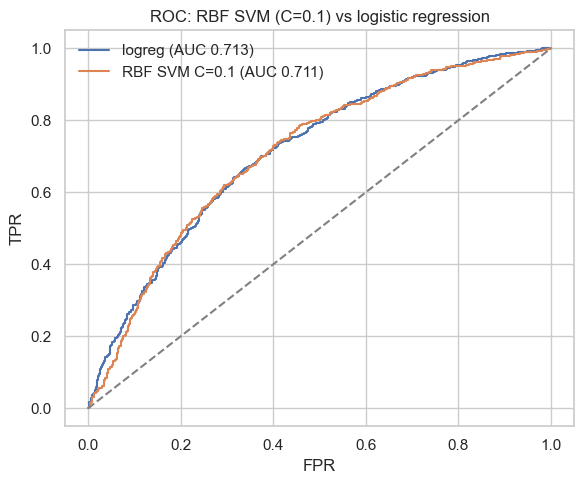

In [6]:
from sklearn.metrics import roc_curve
c_best = 0.1
final = Pipeline([('prep', make_prep()), ('clf', SVC(kernel='rbf', C=c_best))]).fit(X_train, y_train)
base = Pipeline([('prep', make_prep()), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
print("DATASET RESULTS")
print(f"Closed loans (population): 1,303,638 | Clean: {len(df_model):,} (default 20.07%)")
print(f"Analysis sample: {len(df_s):,} balanced 50/50 | Train 4,500 / Test 1,500")
print(f"Winner: RBF SVM (C={c_best}) test acc {final.score(X_test, y_test):.4f} vs logreg {base.score(X_test, y_test):.4f}")
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in [('logreg', base), (f'RBF SVM C={c_best}', final)]:
    sc = pipe.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, sc)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, sc):.3f})")
ax.plot([0, 1], [0, 1], ls='--', c='grey')
ax.set(xlabel='FPR', ylabel='TPR', title='ROC: RBF SVM (C=0.1) vs logistic regression')
ax.legend(frameon=False); fig.tight_layout(); plt.show()


### Part B Findings and Conclusion

The ROC curves for the tuned RBF SVM (`C = 0.1`) and logistic regression nearly overlap (AUC about 0.71 vs 0.71). No free accuracy from the SVM here, but that is the conclusion: on noisy tabular default data, margin maximization ties log loss, the kernel adds flexibility the signal does not reward, and regularization (`C ≈ 0.1`) is what prevents the RBF from memorizing.

In plain terms, the baseline Part B analysis asked whether margin-based learning can predict loan default and whether kernels and regularization matter. On 6,000 balanced Lending Club loans:

* Linear SVM ties logistic regression (accuracy ~0.65–0.66, AUC ~0.71).
* The RBF kernel draws visibly different boundaries but gains nothing, because the signal is noisy and close to linear.
* The `C` sweep is the real lesson — `C = 100` memorizes (train 0.90 / test 0.57) while `C ≈ 0.1` generalizes best (test 0.66).
* Support vectors tell the story throughout: 76% of training rows are SVs (heavy overlap), shrinking as `C` hardens the margin.

The main caveat is that the 50/50 sample flatters accuracy relative to the 20%-default population — ROC-AUC is the transferable metric. Part C below replaces the test-set `C` sweep with a proper cross-validated grid, uses the natural ~20% prevalence, and repeats everything on Taiwan.

## Part C — Proper SVM Tuning: 5-Fold GridSearchCV on Both Datasets

The baseline Part B above picked `C` by looking at test accuracy, which reuses the test set for a decision and makes its score no longer an honest estimate of new-data performance (a mild form of leakage). Part C fixes this:

* The search runs on training folds only (StratifiedKFold, 5 folds); the test set is used once at the end.
* Kernel (linear vs RBF), `C` (margin softness), and `γ` (RBF reach) are searched jointly.
* A shared classification split at the natural ~20% default rate is used, rather than the 50/50 sample, so the SVM results compare directly against logistic regression.
* Everything is repeated on Taiwan.

Kernel SVM training scales roughly as n² to n³, so a 6,000-row stratified subsample of each training set is used to keep 115 fits per dataset feasible. The test sets stay at full size (12,000 and 5,993 rows).

### 7. Shared Classification Setup

To make the Lending Club and Taiwan results directly comparable, both datasets use the same split logic, the same preprocessing structure, and the same cross-validation protocol.

* **Lending Club:** a 60,000-loan random sample of the cleaned closed loans (seed 42), split 80/20 **stratified** on `default` so both parts keep the roughly 20% default rate.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

The `make_prep(num, cat, scale=True)` helper builds a `ColumnTransformer` that standardizes the numerics and one-hot encodes the categoricals. It is always fit inside a pipeline on training folds only, so no test-set leakage occurs.

Stratification matters here because with 20–22% positives, a random split could by chance put noticeably more defaults in one part. Stratifying guarantees equal rates, which makes metrics directly comparable between train and test.

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["log_LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2, stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2, stratify=tw["default"], random_state=SEED)
DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan": (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%} | numeric {len(num)}, categorical {len(cat)}")

from sklearn.svm import SVC

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


### Shared-Setup Findings

* **Lending Club:** train 48,000 × 11 and test 12,000 × 11. Both have a 20.29% default rate, with 6 numeric and 5 categorical features.
* **Taiwan:** train 23,972 × 23 and test 5,993 × 23. Both have a 22.13% default rate, with 20 numeric and 3 categorical features.

Two baselines to keep in mind:

* **Accuracy baseline.** An "everyone repays" rule scores 79.7% on Lending Club and 77.9% on Taiwan.
* **PR-AUC baseline.** A random ranking scores 0.203 on Lending Club and 0.221 on Taiwan.

### 8. GridSearchCV for SVC (Kernel × C × γ), Scored by ROC-AUC

The grid searches jointly over:

* **C (regularization).** Small C gives a wide margin that tolerates misclassified training points (simpler model, more bias). Large C gives a narrow margin that tries to classify every training point (more variance).
* **γ (RBF only).** Controls how far one support vector's influence reaches. A small γ gives smooth, nearly linear boundaries; a large γ gives tight "islands" around individual points, a classic way to overfit.
* **Kernel.** Linear and RBF. The RBF kernel K(x, z) = exp(−γ‖x − z‖²) lets the SVM fit a linear boundary in an implicit, infinite-dimensional feature space without ever computing it.

**Grid:** linear with C ∈ {0.01, 0.1, 1} (3 candidates), plus RBF with C ∈ {0.01, 0.1, 1, 10, 100} × γ ∈ {scale, 0.01, 0.1, 1} (20 candidates). Times 5 folds, that is 115 fits per dataset.

`class_weight="balanced"` is fixed, not tuned, because without it the SVM would flag almost no defaults at the natural prevalence. `return_train_score=True` records the training-fold AUC, so train and validation can be compared — their divergence is the signature of overfitting.

In [15]:
import time
svm_grid = [{"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1]},
            {"clf__kernel": ["rbf"], "clf__C": [0.01, 0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1, 1]}]
svm_gs, svm_sub = {}, {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    Xs, _, ys, _ = train_test_split(Xa, ya, train_size=6000, stratify=ya, random_state=SEED)
    svm_sub[name] = (Xs, ys)
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", SVC(class_weight="balanced", cache_size=1000))])
    t0 = time.time()
    gs = GridSearchCV(pipe, svm_grid, scoring="roc_auc", cv=CV5, n_jobs=-1, return_train_score=True).fit(Xs, ys)
    svm_gs[name] = gs
    r = pd.DataFrame(gs.cv_results_)
    r["gap"] = r["mean_train_score"] - r["mean_test_score"]
    print(f"\n{name}: subsample {Xs.shape}, default {ys.mean():.2%}, search time {time.time()-t0:.0f}s")
    print(f"BEST {gs.best_params_}  CV AUC {gs.best_score_:.4f} +- {r.loc[gs.best_index_, 'std_test_score']:.4f}")
    display(r.sort_values("rank_test_score")[["param_clf__kernel", "param_clf__C", "param_clf__gamma", "mean_train_score",
            "mean_test_score", "std_test_score", "gap", "rank_test_score"]].head(6).round(4))
    print("Most overfit candidates (largest train-CV gap):")
    display(r.sort_values("gap", ascending=False)[["param_clf__kernel", "param_clf__C", "param_clf__gamma", "mean_train_score", "mean_test_score", "gap"]].head(3).round(4))


Lending Club: subsample (6000, 11), default 20.28%, search time 16s
BEST {'clf__C': 0.1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}  CV AUC 0.6823 +- 0.0110


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_train_score,mean_test_score,std_test_score,gap,rank_test_score
8,rbf,0.10,0.01,0.6874,0.6823,0.0110,0.0051,1
12,rbf,1.00,0.01,0.6934,0.6814,0.0131,0.0120,2
9,rbf,0.10,0.1,0.7114,0.6808,0.0094,0.0305,3
0,linear,0.01,NaN,0.6859,0.6807,0.0130,0.0053,4
7,rbf,0.10,scale,0.7144,0.6806,0.0095,0.0338,5
2,linear,1.00,NaN,0.6866,0.6797,0.0130,0.0069,6


Most overfit candidates (largest train-CV gap):


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_train_score,mean_test_score,gap
19,rbf,100.0,scale,0.9825,0.5740,0.4085
22,rbf,100.0,1,1.0000,0.5933,0.4067
18,rbf,10.0,1,1.0000,0.5934,0.4066



Taiwan: subsample (6000, 23), default 22.13%, search time 11s
BEST {'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}  CV AUC 0.7620 +- 0.0085


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_train_score,mean_test_score,std_test_score,gap,rank_test_score
12,rbf,1.0,0.01,0.7818,0.7620,0.0085,0.0199,1
7,rbf,0.1,scale,0.7808,0.7599,0.0101,0.0209,2
16,rbf,10.0,0.01,0.8144,0.7579,0.0086,0.0565,3
11,rbf,1.0,scale,0.8364,0.7564,0.0093,0.0799,4
8,rbf,0.1,0.01,0.7603,0.7526,0.0075,0.0077,5
9,rbf,0.1,0.1,0.7901,0.7514,0.0131,0.0388,6


Most overfit candidates (largest train-CV gap):


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_train_score,mean_test_score,gap
18,rbf,10.0,1,0.9990,0.6366,0.3624
22,rbf,100.0,1,0.9998,0.6382,0.3615
21,rbf,100.0,0.1,0.9857,0.6415,0.3443


### Grid Findings

**Lending Club** (6,000 rows, 20.28% default; search time ~16 s):

* Best: RBF, C = 0.1, γ = 0.01, with CV AUC 0.6823 ± 0.0110 and a train–CV gap of only 0.005.
* The top 6 candidates span 0.6797 to 0.6823, including linear C = 0.01 at 0.6807. All are within one fold-SD (about 0.011).
* Most overfit: RBF C = 100, γ = scale reaches train AUC 0.98 but CV 0.574 (gap 0.41). RBF γ = 1 with C ≥ 10 hits train AUC 1.000 with CV around 0.59.

**Taiwan** (6,000 rows, 22.13% default; ~11 s):

* Best: RBF, C = 1, γ = 0.01, with CV AUC 0.7620 ± 0.0085 (gap 0.020).
* Next best: RBF C = 0.1, γ = scale at 0.7599.
* No linear candidate is in the top 6.
* Most overfit: γ = 1 with C ≥ 10 reaches train AUC ~0.999 and CV ~0.64 (gap ~0.36).

Four things stand out:

* **Small γ wins on both datasets.** γ = 0.01 is a wide, smooth kernel, close to linear. The winning models are only mildly nonlinear.
* **Lending Club gains nothing from the kernel.** The linear SVM is statistically tied with the best RBF.
* **Taiwan gains a little from the kernel.** The best RBF beats every linear candidate, which is consistent with the curved `PAY_1` pattern (default jumps at 2+ months late).
* **Train AUC of 1.000 with CV around 0.59 is textbook overfitting.** With large γ and large C, every training point becomes its own island.

Fold SDs around 0.01 mean differences below about 0.01 AUC are not meaningful.

### 9. CV AUC vs C — The Regularization Curve

This step replaces the original test-set `C` sweep with a cross-validated version: one line per γ (RBF) plus the linear kernel, with solid lines for validation AUC and dashed lines for training AUC.

What to look for: where each validation curve peaks, which γ values open a large train/validation gap, and whether any RBF setting clearly beats the linear kernel.

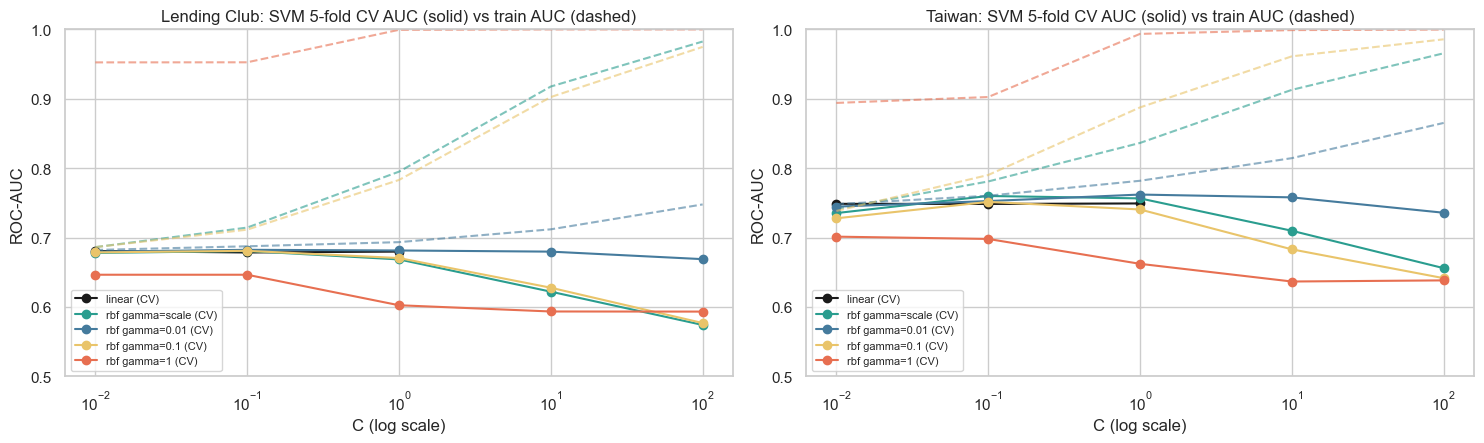

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, name in zip(axes, DATA):
    r = pd.DataFrame(svm_gs[name].cv_results_)
    lin = r[r.param_clf__kernel == "linear"]
    ax.plot(lin.param_clf__C.astype(float), lin.mean_test_score, "k-o", label="linear (CV)")
    for g, col in zip(["scale", 0.01, 0.1, 1], ["#2a9d8f", "#457b9d", "#e9c46a", "#e76f51"]):
        s = r[(r.param_clf__kernel == "rbf") & (r.param_clf__gamma.astype(str) == str(g))]
        ax.plot(s.param_clf__C.astype(float), s.mean_test_score, "-o", color=col, label=f"rbf gamma={g} (CV)")
        ax.plot(s.param_clf__C.astype(float), s.mean_train_score, "--", color=col, alpha=.6)
    ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("ROC-AUC")
    ax.set_title(f"{name}: SVM 5-fold CV AUC (solid) vs train AUC (dashed)"); ax.set_ylim(0.5, 1.0); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w5_svm_cv_curve.png", dpi=150, bbox_inches="tight"); plt.show()

### CV Curve Findings

* **Lending Club.** The CV curves (solid) sit around 0.66–0.68 for γ ∈ {0.01, scale, 0.1} at small and moderate `C`. As `C` grows they fall, fastest for γ = 1 (down to about 0.59). The dashed training curves rise toward 1.0 for large γ and `C`. The linear line is flat at about 0.68 across `C`.
* **Taiwan.** Same shape at a higher level (peak about 0.76 at γ = 0.01, C = 1). γ = 1 opens the widest train/validation gap.

As `C` grows (and with large γ), training AUC keeps climbing while validation AUC peaks and then falls — the model is fitting noise. The regularized region that generalizes is small γ with a moderate `C` (0.1–1). The linear kernel's flat curve shows it is insensitive to `C` here: with 6,000 rows and 30–40 features, the linear margin is already well determined.

### 10. Final Held-Out Test — Tuned SVM vs Logistic Regression

This is the honest comparison. Each model is refit on the same 6,000-row training subsample and scored once on the full test set. Logistic regression is also refit on the full training set, to show how much the SVM's subsampling costs.

For the SVM, the `decision_function` (signed distance to the boundary) is used as the score for ROC-AUC and PR-AUC; class labels come from the boundary at 0.

In [17]:
from sklearn.linear_model import LogisticRegression
w5_rows = []
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    Xs, ys = svm_sub[name]
    svm = svm_gs[name].best_estimator_
    sc = svm.decision_function(Xb); pred = (sc >= 0).astype(int)
    w5_rows.append({"dataset": name, "model": f"SVM {svm_gs[name].best_params_}", "train_rows": len(ys),
                    "accuracy": accuracy_score(yb, pred), "precision": precision_score(yb, pred), "recall": recall_score(yb, pred),
                    "f1": f1_score(yb, pred), "roc_auc": roc_auc_score(yb, sc), "pr_auc": average_precision_score(yb, sc),
                    "n_SV": int(svm.named_steps["clf"].n_support_.sum())})
    for rows_lbl, (XX, yy) in [("6k", (Xs, ys)), ("full", (Xa, ya))]:
        lr = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(XX, yy)
        w5_rows.append({"dataset": name, "model": f"LogReg balanced ({rows_lbl})", "train_rows": len(yy), **{k: v for k, v in scores(yb, lr.predict_proba(Xb)[:, 1]).items() if k != "threshold"}})
w5 = pd.DataFrame(w5_rows)
display(w5.round(4))

,dataset,model,train_rows,accuracy,precision,recall,f1,roc_auc,pr_auc,n_SV
0,Lending Club,"SVM {'clf__C': 0.1, 'clf__gamma': 0.01, 'clf__...",6000,0.6769,0.3357,0.6049,0.4318,0.7014,0.3627,5049.0
1,Lending Club,LogReg balanced (6k),6000,0.6583,0.3259,0.6398,0.4318,0.7087,0.3709,NaN
2,Lending Club,LogReg balanced (full),48000,0.6437,0.3212,0.6793,0.4362,0.7126,0.3779,NaN
3,Taiwan,"SVM {'clf__C': 1, 'clf__gamma': 0.01, 'clf__ke...",6000,0.7492,0.4496,0.5950,0.5122,0.7443,0.4890,4090.0
4,Taiwan,LogReg balanced (6k),6000,0.7215,0.4134,0.6176,0.4953,0.7415,0.4921,NaN
5,Taiwan,LogReg balanced (full),23972,0.7307,0.4247,0.6124,0.5015,0.7422,0.5010,NaN


### Final Test Findings

| Dataset | Model | Train rows | ROC-AUC | PR-AUC | Recall | F1 | Support vectors |
|---|---|---|---|---|---|---|---|
| Lending Club | RBF SVM C = 0.1, γ = 0.01 | 6,000 | 0.7014 | 0.3627 | 0.605 | 0.432 | **5,049 (84%)** |
| Lending Club | LogReg balanced | 6,000 | 0.7087 | 0.3709 | 0.640 | 0.432 | — |
| Lending Club | LogReg balanced | 48,000 | **0.7126** | **0.3779** | 0.679 | 0.436 | — |
| Taiwan | RBF SVM C = 1, γ = 0.01 | 6,000 | **0.7443** | 0.4890 | 0.595 | **0.512** | 4,090 (68%) |
| Taiwan | LogReg balanced | 6,000 | 0.7415 | 0.4921 | 0.618 | 0.495 | — |
| Taiwan | LogReg balanced | 23,972 | 0.7422 | **0.5010** | 0.612 | 0.502 | — |

Four observations:

* **Lending Club.** The tuned SVM loses to logistic regression trained on the same 6,000 rows (AUC 0.701 vs 0.709) and to logistic regression on all 48,000 rows (0.713).
* **Taiwan.** The SVM edges logistic regression on ROC-AUC (+0.002–0.003) and F1 (+0.01–0.017), but trails slightly on PR-AUC. Effectively a tie.
* **Support vectors.** 84% of Lending Club training rows (and 68% of Taiwan's) are support vectors. The classes overlap so heavily that almost every point sits inside the soft margin, which is exactly the regime where an SVM has no efficiency advantage.
* **Scalability.** The SVM is limited to a subsample by cost, while logistic regression uses all the data. On Lending Club that difference alone is worth about 0.004 AUC.

The kernel trick does not break the linear ceiling (about 0.71 and 0.74 AUC) on either dataset. The SVM here is a well-documented margin-based comparison model, not the overall champion. The proper CV tuning makes that conclusion defensible rather than an artifact of test-set selection.

With engineered interaction features, or many more rows (using approximate kernels), SVM results might change.

### 11. Summary

In [18]:
for name in DATA:
    d_ = w5[w5.dataset == name].set_index("model")
    print(f"{name}: best SVM AUC {d_.roc_auc.iloc[0]:.4f} vs LogReg(6k) {d_.roc_auc.iloc[1]:.4f} vs LogReg(full) {d_.roc_auc.iloc[2]:.4f}")

Lending Club: best SVM AUC 0.7014 vs LogReg(6k) 0.7087 vs LogReg(full) 0.7126
Taiwan: best SVM AUC 0.7443 vs LogReg(6k) 0.7415 vs LogReg(full) 0.7422


## 12. Conclusion

* **Best tuned SVMs (test ROC-AUC):** Lending Club 0.701 (vs logistic 0.709–0.713), Taiwan 0.744 (vs logistic 0.742). The optimal kernels are wide (γ = 0.01), which means the winning models are nearly linear in the original feature space.
* **The kernel trick does not help on either dataset.** On Lending Club the linear SVM ties the best RBF; on Taiwan the RBF edge is small enough to sit inside one fold standard deviation.
* **Overfitting is the main SVM risk.** Large `C` combined with large γ reaches training AUC of 1.00 with validation AUC around 0.59–0.64. The regularized region that generalizes is small γ with moderate `C`.
* **Support vectors tell the story throughout.** Between 68% and 84% of the training rows are support vectors, which means the classes overlap heavily and the boundary is determined by a crowd rather than by a few decisive points. This is the opposite of the regime where an SVM is most efficient.

### Key Limitations

The SVM analysis here is cost-bound: training scales roughly as n² to n³, so the SVM is limited to a 6,000-row subsample while logistic regression trains on the full 48,000 or 23,972 rows. On Lending Club the subsampling alone costs about 0.004 AUC, which is not catastrophic but is enough to lose a close head-to-head comparison.

The reported odds ratios, coefficients, and performance numbers describe associations within fitted models rather than causal effects. Approximate-kernel methods (Nyström, random Fourier features) could in principle scale the SVM to full training sets at modest accuracy cost; that is outside the scope of this analysis.

Overall, the SVM is a documented alternative to logistic regression at a comparable AUC, not an improvement on it on these two datasets.